# 02 — Robust Sign Reading Under Realistic Camera Conditions

The baseline in notebook `01` reads a clean, front-facing sign. A robot camera rarely gets that: boards appear **rotated, small and distant, motion-blurred, under-exposed or noisy**.

This notebook:
1. Generates controlled stress-test images that simulate these conditions
2. Measures where full-frame OCR (the baseline) fails
3. Builds a pipeline: **colour ROI detection → deskew → adaptive enhancement → constrained OCR → fuzzy command matching**
4. Combines everything into a single perception function, `robot_see(frame)`, and a multi-strategy version, `robot_see_v2(frame)`, that recovers the remaining failure cases
5. Reports the speed–accuracy trade-off and the known limitations

In [1]:
# Setup: install dependencies if missing (on Colab, choose Runtime -> Change runtime type -> T4 GPU)
import importlib.util, subprocess, sys
missing = [p for p in ("ultralytics", "easyocr") if importlib.util.find_spec(p) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

import warnings
warnings.filterwarnings("ignore")
import torch
DEVICE = "GPU" if torch.cuda.is_available() else "CPU"
print("Dependencies ready | running on:", DEVICE)

Dependencies ready | running on: CPU


In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def show(images, titles, cols=3, size=4, save=None):
    """Display BGR or grayscale images in a grid (works in Colab and Jupyter)."""
    rows = (len(images) + cols - 1) // cols
    plt.figure(figsize=(cols * size, rows * size * 0.75))
    for i, (im, t) in enumerate(zip(images, titles)):
        plt.subplot(rows, cols, i + 1)
        plt.imshow(im if im.ndim == 2 else cv2.cvtColor(im, cv2.COLOR_BGR2RGB),
                   cmap="gray" if im.ndim == 2 else None)
        plt.title(t)
        plt.axis("off")
    plt.tight_layout()
    if save:
        plt.savefig(save, dpi=110, bbox_inches="tight")
    plt.show()

import os
os.makedirs("results", exist_ok=True)

## 1. Helper functions
- `make_sign` — renders a red board with white text
- `place_sign` — pastes the board onto a background at a given position, size and rotation (a simulated camera view)
- `find_red_sign` — finds the red board by colour (HSV), filters candidates by shape, and returns a deskewed crop
- `enhance` — prepares a crop for OCR: contrast stretch, CLAHE, denoising, upscaling and sharpening

In [3]:
def make_sign(text, w=400, h=200):
    sign = np.full((h, w, 3), 255, dtype=np.uint8)
    cv2.rectangle(sign, (10, 10), (w - 10, h - 10), (0, 0, 200), -1)
    scale = 3 if len(text) <= 4 else 2.2
    (tw, th), _ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, scale, 8)
    cv2.putText(sign, text, ((w - tw) // 2, (h + th) // 2),
                cv2.FONT_HERSHEY_SIMPLEX, scale, (255, 255, 255), 8)
    return sign


def place_sign(background, sign, x, y, width=260, angle=0):
    """Paste a resized, rotated sign onto the background at (x, y)."""
    bg = background.copy()
    h = int(sign.shape[0] * width / sign.shape[1])
    s = cv2.resize(sign, (width, h))
    diag = int(np.hypot(width, h)) + 4
    canvas = np.zeros((diag, diag, 3), np.uint8)
    mask = np.zeros((diag, diag), np.uint8)
    ox, oy = (diag - width) // 2, (diag - h) // 2
    canvas[oy:oy + h, ox:ox + width] = s
    mask[oy:oy + h, ox:ox + width] = 255
    M = cv2.getRotationMatrix2D((diag / 2, diag / 2), angle, 1.0)
    canvas = cv2.warpAffine(canvas, M, (diag, diag))
    mask = cv2.warpAffine(mask, M, (diag, diag))
    roi = bg[y:y + diag, x:x + diag]
    roi[mask > 0] = canvas[mask > 0]
    return bg


def find_red_sign(frame, min_area=800):
    """Locate a red rectangular board; return (deskewed crop, box corners, mask)."""
    smooth = cv2.medianBlur(frame, 7)                      # suppress sensor noise
    hsv = cv2.cvtColor(smooth, cv2.COLOR_BGR2HSV)
    m1 = cv2.inRange(hsv, (0, 100, 30), (10, 255, 255))    # red wraps around hue 0
    m2 = cv2.inRange(hsv, (170, 100, 30), (180, 255, 255))
    mask = cv2.bitwise_or(m1, m2)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))    # remove specks
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, np.ones((15, 15), np.uint8)) # fill letter holes
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    good = []
    for c in contours:
        area = cv2.contourArea(c)
        if area < min_area or area > 0.5 * frame.shape[0] * frame.shape[1]:
            continue
        (_, _), (w, h), _ = cv2.minAreaRect(c)
        if w * h == 0:
            continue
        fill = area / (w * h)               # how rectangular the blob is
        ratio = max(w, h) / min(w, h)       # board aspect ratio
        if fill > 0.7 and 1.2 < ratio < 4:
            good.append(c)
    if not good:
        return None, None, mask

    c = max(good, key=cv2.contourArea)
    (cx, cy), (w, h), angle = cv2.minAreaRect(c)
    if w < h:
        angle -= 90
        w, h = h, w
    while angle > 45:                        # normalise angle to [-45, 45]
        angle -= 180
    while angle < -45:
        angle += 180
    M = cv2.getRotationMatrix2D((cx, cy), angle, 1.0)
    rotated = cv2.warpAffine(frame, M, (frame.shape[1], frame.shape[0]))
    crop = cv2.getRectSubPix(rotated, (int(w), int(h)), (cx, cy))
    box = cv2.boxPoints(((cx, cy), (w, h), angle)).astype(int)
    return crop, box, mask


def enhance(img):
    """Contrast stretch -> CLAHE -> median denoise -> upscale -> unsharp mask."""
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) if img.ndim == 3 else img
    gray = cv2.normalize(gray, None, 0, 255, cv2.NORM_MINMAX)
    gray = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8)).apply(gray)
    gray = cv2.medianBlur(gray, 5)
    h, w = gray.shape
    if max(h, w) < 600:
        f = 600 / max(h, w)
        gray = cv2.resize(gray, None, fx=f, fy=f, interpolation=cv2.INTER_CUBIC)
    blur = cv2.GaussianBlur(gray, (0, 0), 3)
    return cv2.addWeighted(gray, 1.6, blur, -0.6, 0)

## 2. Stress-test images
A corridor-like gradient background with sensor noise, a **LEFT** board, and six conditions a moving robot camera produces.

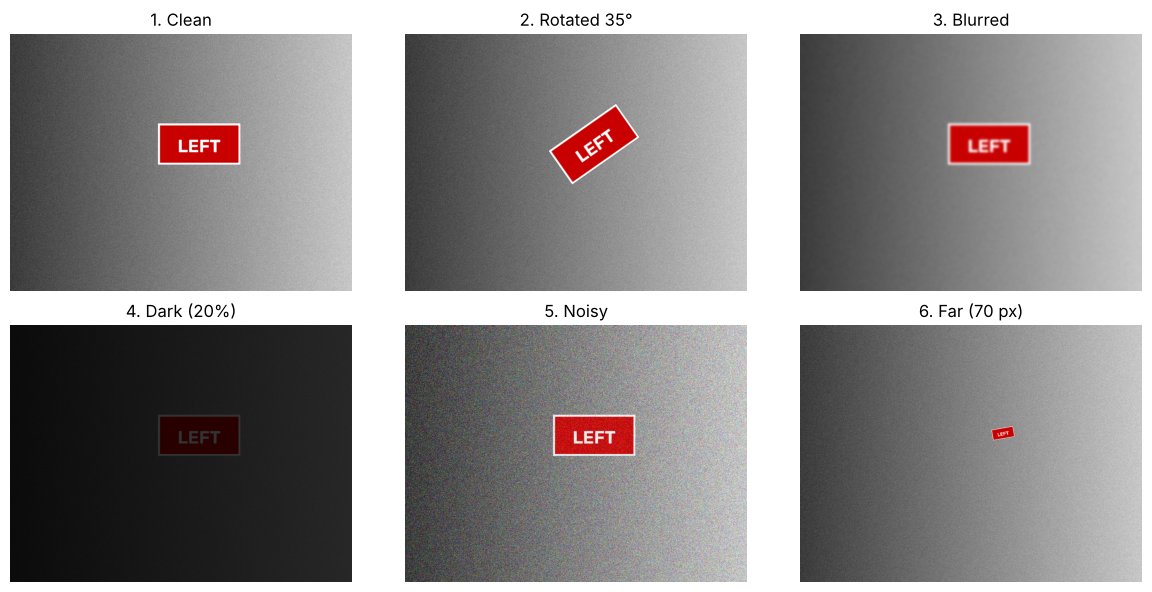

In [4]:
np.random.seed(0)
g = np.tile(np.linspace(60, 200, 1080, dtype=np.float32), (810, 1))
g += np.random.normal(0, 12, g.shape)
background = cv2.cvtColor(np.clip(g, 0, 255).astype(np.uint8), cv2.COLOR_GRAY2BGR)

sign = make_sign("LEFT")

tests = {}
tests["1. Clean"]        = place_sign(background, sign, 450, 200, width=260, angle=0)
tests["2. Rotated 35°"]  = place_sign(background, sign, 450, 200, width=260, angle=35)
tests["3. Blurred"]      = cv2.GaussianBlur(tests["1. Clean"], (21, 21), 0)
tests["4. Dark (20%)"]   = (tests["1. Clean"] * 0.2).astype(np.uint8)
noise = np.random.normal(0, 45, tests["1. Clean"].shape)
tests["5. Noisy"]        = np.clip(tests["1. Clean"] + noise, 0, 255).astype(np.uint8)
tests["6. Far (70 px)"]  = place_sign(background, sign, 600, 300, width=70, angle=10)

show(list(tests.values()), list(tests.keys()), save="results/stress_tests.png")

## 3. Baseline: full-frame OCR
The whole frame is passed to EasyOCR, as in notebook `01`. The highest-confidence reading is kept.

In [5]:
import easyocr
reader = easyocr.Reader(["en"], gpu=torch.cuda.is_available(), verbose=False)

def ocr_best(img, **kw):
    """Return (text, confidence) of the most confident OCR result."""
    res = reader.readtext(img, **kw)
    if not res:
        return "-", 0.0
    _, text, conf = max(res, key=lambda r: r[2])
    return text, float(conf)

baseline = {}
print(f"{'Test':18s} {'Read':8s} Confidence")
print("-" * 38)
for name, img in tests.items():
    text, conf = ocr_best(img)
    baseline[name] = (text, conf)
    print(f"{name:18s} {text:8s} {conf:.2f}")

Test               Read     Confidence
--------------------------------------


1. Clean           LEFT     0.98


2. Rotated 35°     LEFT     0.94


3. Blurred         LefT     0.72


4. Dark (20%)      LeFT     0.62


5. Noisy           LEFT     1.00


6. Far (70 px)     Left     0.86


## 4. Pipeline: locate → deskew → enhance → read
Instead of running OCR on the full frame, first find a **Region of Interest (ROI)**. The board is red, so an HSV colour mask plus shape filtering (fill ratio, aspect ratio) is a cheap and effective locator.

Deskewed board crops:


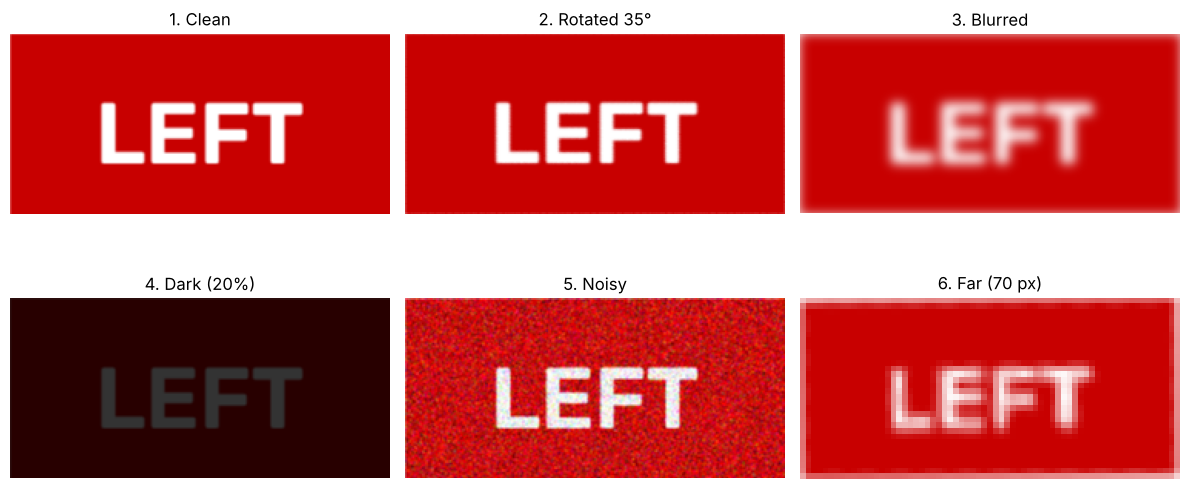

After enhancement (OCR input):


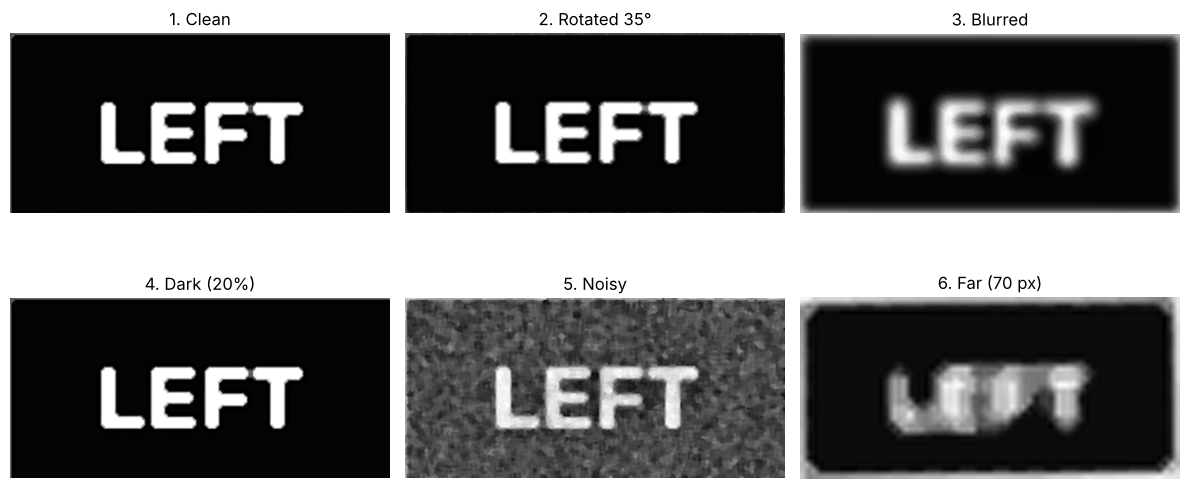

In [6]:
crops, enhanced, titles = [], [], []
for name, img in tests.items():
    crop, box, mask = find_red_sign(img)
    if crop is None:
        crop = img
        titles.append(name + " (no board found)")
    else:
        titles.append(name)
    crops.append(crop)
    enhanced.append(enhance(crop))

print("Deskewed board crops:")
show(crops, titles)
print("After enhancement (OCR input):")
show(enhanced, titles, save="results/enhanced_crops.png")

In [7]:
ALLOW = "ABCDEFGHIJKLMNOPQRSTUVWXYZ"   # constrain OCR to upper-case letters

pipeline = {}
print(f"{'Test':18s} {'Baseline OCR':16s} {'Pipeline':16s}")
print("-" * 52)
for (name, _), img in zip(tests.items(), enhanced):
    t2, c2 = ocr_best(img, allowlist=ALLOW)
    pipeline[name] = (t2, c2)
    t1, c1 = baseline[name]
    print(f"{name:18s} {t1:8s} {c1:.2f}    {t2:8s} {c2:.2f}")

Test               Baseline OCR     Pipeline        
----------------------------------------------------


1. Clean           LEFT     0.98    LEFT     1.00


2. Rotated 35°     LEFT     0.94    LEFT     1.00


3. Blurred         LefT     0.72    LEFT     0.90


4. Dark (20%)      LeFT     0.62    LEFT     1.00


5. Noisy           LEFT     1.00    LEFT     1.00


6. Far (70 px)     Left     0.86    -        0.00


**Observations**
- The pipeline raises confidence where the baseline is weakest: **blurred** and **dark** frames.
- It reads clean upper-case text (`LEFT`) instead of mixed-case guesses (`LefT`, `LeFT`) thanks to the allow-list.
- It **fails on the far, 70-pixel board**: upscaling and sharpening destroy the few pixels that carry the letters, while the baseline still reads it. Preprocessing is not free — it can hurt.

For a robot, the far-sign case also has a *behavioural* fix: move closer and read again.

## 5. Full perception function: `robot_see(frame)`
1. YOLOv8 detects general objects (people, chairs, ...)
2. The board is located, deskewed, enhanced and read
3. **Fuzzy matching** maps imperfect readings (`LEFI`, `ST0P`) to the nearest valid command
4. The function returns a decision and an annotated frame

1. Clean           -> {'objects': [], 'text': 'LEFT', 'conf': 1.0, 'command': 'LEFT', 'action': 'turn left'}


2. Rotated 35°     -> {'objects': [], 'text': 'LEFT', 'conf': 1.0, 'command': 'LEFT', 'action': 'turn left'}


3. Blurred         -> {'objects': [], 'text': 'LEFT', 'conf': 0.9, 'command': 'LEFT', 'action': 'turn left'}


4. Dark (20%)      -> {'objects': [], 'text': 'LEFT', 'conf': 1.0, 'command': 'LEFT', 'action': 'turn left'}


5. Noisy           -> {'objects': [], 'text': 'LEFT', 'conf': 1.0, 'command': 'LEFT', 'action': 'turn left'}


6. Far (70 px)     -> {'objects': [], 'text': '-', 'conf': 0.0, 'command': None, 'action': 'no command - keep moving'}


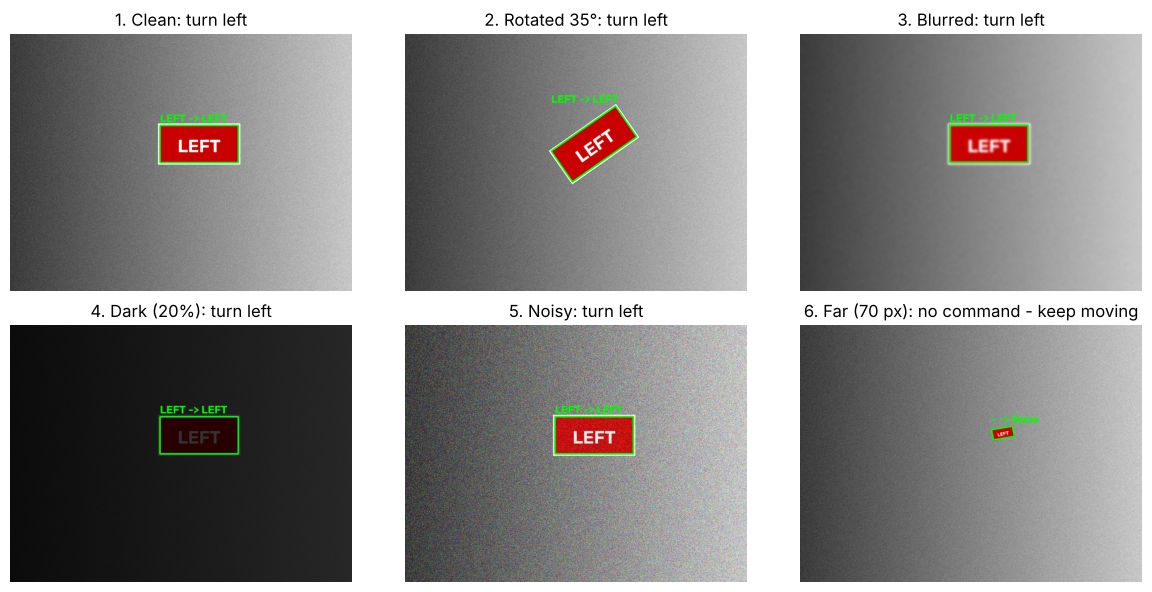

In [8]:
from ultralytics import YOLO
import difflib

model = YOLO("yolov8n.pt")
COMMANDS = {"STOP": "stop", "LEFT": "turn left", "RIGHT": "turn right", "GO": "move forward"}

def match_command(text):
    """Fuzzy-match OCR text to a command, e.g. 'LEFI' -> 'LEFT', 'ST0P' -> 'STOP'."""
    text = text.upper().replace("0", "O").replace("1", "I").replace("5", "S")
    m = difflib.get_close_matches(text, COMMANDS.keys(), n=1, cutoff=0.6)
    return m[0] if m else None

def robot_see(frame, min_conf=0.3):
    r = model(frame, verbose=False)[0]
    objects = [model.names[int(b.cls)] for b in r.boxes if float(b.conf) > 0.4]

    crop, box, _ = find_red_sign(frame)
    text, conf = "-", 0.0
    if crop is not None:
        text, conf = ocr_best(enhance(crop), allowlist=ALLOW)

    cmd = match_command(text) if conf >= min_conf else None
    action = COMMANDS[cmd] if cmd else "no command - keep moving"

    vis = r.plot()
    if box is not None:
        cv2.drawContours(vis, [box], 0, (0, 255, 0), 4)
        cv2.putText(vis, f"{text} -> {cmd}", (box[:, 0].min(), max(30, box[:, 1].min() - 10)),
                    cv2.FONT_HERSHEY_SIMPLEX, 1.2, (0, 255, 0), 3)
    return {"objects": objects, "text": text, "conf": round(conf, 2),
            "command": cmd, "action": action}, vis

visuals, vtitles = [], []
for name, img in tests.items():
    result, vis = robot_see(img)
    print(f"{name:18s} -> {result}")
    visuals.append(vis)
    vtitles.append(f"{name}: {result['action']}")
show(visuals, vtitles)

## 6. Harder cases and a multi-strategy reader: `robot_see_v2`
Pushing the conditions further exposes new failure modes of `robot_see`:
- **Rotation beyond ~60°:** the deskew step normalises the angle to ±45°, so at 85° or 120° the crop comes out upside down and OCR reads garbage (`LJJ`).
- **Extreme darkness (3% light):** the colour mask finds no board at all.
- **Small, distant boards:** below `min_area` the board is never located, and enhancement destroys detail anyway.

`read_sign` runs several complementary strategies and picks the most confident result **that matches a valid command**:
1. board crop + enhancement, read upright and rotated 180°
2. board crop without enhancement (preserves small text)
3. full frame (fallback when no board is located)
4. full frame + enhancement (fallback for very dark frames)

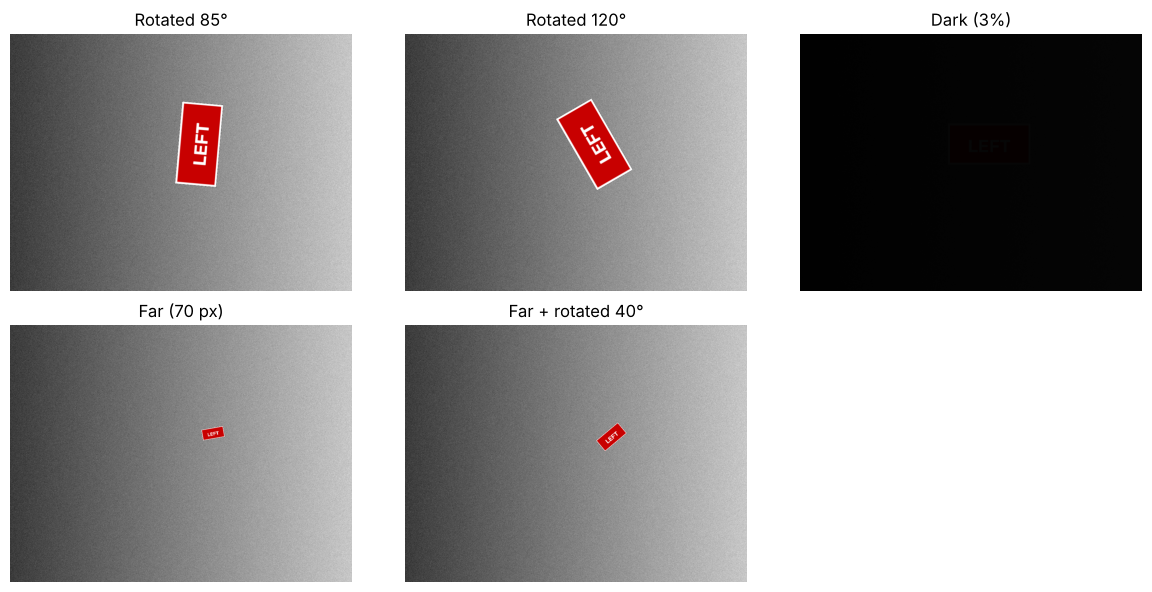

Timing measured on: CPU

Test               robot_see              robot_see_v2           Strategy / time
--------------------------------------------------------------------------------------------


Rotated 85°        LJJ 1.00 -> None       LEFT 1.00 -> LEFT      board, no enhance / 17343 ms


Rotated 120°       LJJ 0.99 -> None       LEFT 1.00 -> LEFT      board + enhance / 16753 ms


Dark (3%)          - 0.00 -> None         LEFT 1.00 -> LEFT      full frame + enhance / 15007 ms


Far (70 px)        - 0.00 -> None         Left 0.86 -> LEFT      full frame / 16063 ms


Far + rotated 40°  I 0.03 -> None         LEFT 1.00 -> LEFT      board, no enhance / 16292 ms

Recovered 5/5 cases that robot_see failed.


In [9]:
import time

def read_sign(frame):
    candidates = []                                    # (text, confidence, strategy)
    crop, box, _ = find_red_sign(frame)
    if crop is not None:
        t, c = ocr_best(enhance(crop), allowlist=ALLOW, rotation_info=[180])
        candidates.append((t, c, "board + enhance"))
        t, c = ocr_best(crop, rotation_info=[180])
        candidates.append((t, c, "board, no enhance"))
    t, c = ocr_best(frame, rotation_info=[180])
    candidates.append((t, c, "full frame"))
    t, c = ocr_best(enhance(frame), allowlist=ALLOW)
    candidates.append((t, c, "full frame + enhance"))

    valid = [x for x in candidates if match_command(x[0])]
    best = max(valid or candidates, key=lambda x: x[1])
    return best, box

def robot_see_v2(frame, min_conf=0.3):
    r = model(frame, verbose=False)[0]
    objects = [model.names[int(b.cls)] for b in r.boxes if float(b.conf) > 0.4]
    (text, conf, method), box = read_sign(frame)
    cmd = match_command(text) if conf >= min_conf else None
    action = COMMANDS[cmd] if cmd else "no command - keep moving"
    vis = r.plot()
    if box is not None:
        cv2.drawContours(vis, [box], 0, (0, 255, 0), 4)
    return {"objects": objects, "text": text, "conf": round(float(conf), 2),
            "method": method, "command": cmd, "action": action}, vis

hard = {
    "Rotated 85°":       place_sign(background, sign, 450, 200, width=260, angle=85),
    "Rotated 120°":      place_sign(background, sign, 450, 200, width=260, angle=120),
    "Dark (3%)":         (place_sign(background, sign, 450, 200, width=260) * 0.03).astype(np.uint8),
    "Far (70 px)":       place_sign(background, sign, 600, 300, width=70, angle=10),
    "Far + rotated 40°": place_sign(background, sign, 600, 300, width=90, angle=40),
}
show(list(hard.values()), list(hard.keys()), save="results/hard_cases.png")

print(f"Timing measured on: {DEVICE}")
print()
print(f"{'Test':18s} {'robot_see':22s} {'robot_see_v2':22s} Strategy / time")
print("-" * 92)
hard_rows = []
for name, img in hard.items():
    old, _ = robot_see(img)
    t0 = time.time()
    new, _ = robot_see_v2(img)
    ms = (time.time() - t0) * 1000
    o = f"{old['text']} {old['conf']:.2f} -> {old['command']}"
    n = f"{new['text']} {new['conf']:.2f} -> {new['command']}"
    hard_rows.append((name, old, new, ms))
    print(f"{name:18s} {o:22s} {n:22s} {new['method']} / {ms:.0f} ms")

recovered = sum(1 for _, o, n, _ in hard_rows if o["command"] is None and n["command"] == "LEFT")
print(f"\nRecovered {recovered}/{len(hard_rows)} cases that robot_see failed.")

**Speed–accuracy trade-off.** Running four OCR strategies measured at about 0.5–0.7 s per frame on a Colab T4 GPU and about 15 s on a 2-core CPU (the timing shown above), far slower than a 30 fps camera. Practical options for a real robot:
- run OCR only when a board-like region is detected, or only every N-th frame
- stop early once one strategy returns a valid command with high confidence
- for distant signs, use a behavioural fix: approach the board, then read again

## 7. Test on real or realistic photos
Put photos of red boards with `STOP` / `LEFT` / `RIGHT` / `GO` in `test_images/` and run the cell below. It prints every strategy's result, which helps explain each pass or failure.

In an earlier run on six realistic photos the pipeline passed **5 of 6** scenes (see the README): it read a front-view STOP board where YOLO's own "stop sign" detection agreed with OCR; recovered a distant RIGHT sign and a STOP board on a red brick wall through the full-frame fallback; read a dark, blurred GO sign; and produced no false command in an empty corridor containing a red fire extinguisher. It **failed on a LEFT board viewed at about 45°**, because perspective turns the board into a trapezoid and the rotation-only deskew cannot correct it.

In [10]:
import glob

def all_candidates(frame):
    out = []
    crop, _, _ = find_red_sign(frame)
    if crop is not None:
        out.append(("board + enhance",) + ocr_best(enhance(crop), allowlist=ALLOW, rotation_info=[180]))
        out.append(("board, no enhance",) + ocr_best(crop, rotation_info=[180]))
    out.append(("full frame",) + ocr_best(frame, rotation_info=[180]))
    out.append(("full frame + enhance",) + ocr_best(enhance(frame), allowlist=ALLOW))
    return out, crop

paths = sorted(glob.glob("test_images/*.jpg") + glob.glob("test_images/*.png"))
if not paths:
    print("No images in test_images/ - skipping.")

summary = []
for p in paths:
    frame = cv2.imread(p)
    if frame is None:
        print(f"Could not read {p}")
        continue
    h, w = frame.shape[:2]
    if max(h, w) > 1280:
        f = 1280 / max(h, w)
        frame = cv2.resize(frame, None, fx=f, fy=f)

    t0 = time.time()
    result, vis = robot_see_v2(frame)
    ms = (time.time() - t0) * 1000
    print("=" * 70)
    print(f"{os.path.basename(p)} | objects: {result['objects']}")
    print(f"  read: {result['text']} ({result['conf']}) via {result['method']} -> {result['action']} | {ms:.0f} ms")
    cands, crop = all_candidates(frame)
    for method, text, conf in cands:
        print(f"    - {method:22s} {text:10s} {conf:.2f} -> {match_command(text)}")
    show([vis] + ([crop] if crop is not None else []),
         [result["action"]] + (["board crop"] if crop is not None else []), cols=2, size=6)
    summary.append((os.path.basename(p), result["text"], result["conf"], result["method"], result["command"], round(ms)))

for row in summary:
    print(row)

No images in test_images/ - skipping.


## 8. Summary and limitations
**What worked**
- Colour ROI + deskew + enhancement + allow-listed OCR clearly improves blurred and dark frames over full-frame OCR.
- Fuzzy matching makes command decisions tolerant to single-character OCR errors.
- A multi-strategy reader recovers the failure cases of the single-path pipeline (large rotations, 3% illumination, distant boards).

**Known limitations**
- **Perspective distortion:** deskew handles in-plane rotation only. Oblique views need 4-corner detection and `cv2.getPerspectiveTransform`, as in document-scanner apps.
- **Colour-only localisation is a weak cue:** red backgrounds (brick walls, red objects) produce false candidates. Checking for text inside candidate regions, or training a small sign detector, would help.
- **`min_area` trade-off:** a lower threshold finds distant boards but admits more red blobs.
- **Speed:** multi-strategy OCR is too slow for every frame; it should be gated by detection.
- **Synthetic data is cleaner than a real camera:** results must be confirmed with a real robot camera.

**Next step:** wrap `robot_see_v2` as a ROS 2 node that subscribes to a camera topic and publishes velocity commands on a simulated robot.